# Stratified Shuffle Split

- When building machine learning models, one of the most important steps is splitting your dataset into training and test sets. This ensures your model is evaluated on data it has never seen before, which is critical for assessing its ability to generalize.

------------

## The Problem of Data Snooping Bias

- Data snooping bias occurs when information from the test set leaks into the training process. This can lead to overly optimistic performance metrics and models that don’t perform well in real-world scenarios.

To avoid this, the test set must be isolated before any data exploration, feature selection, or model training begins.

----------

---------

## 1. Random Sampling: A Basic Approach

A simple method to split the data is to randomly shuffle it and then divide it:

In [ ]:
import numpy as np

def shuffle_and_split_data(data, test_ratio):
    np.random.seed(42)  # Set the seed for reproducibility
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

- Setting the random seed (e.g., with np.random.seed(42)) ensures consistency across runs — this is crucial for debugging and comparing models fairly.

- However, pure random sampling might not always be reliable, especially if the dataset contains important patterns that are not evenly distributed.

==============

--------------------

## 2. Stratified Sampling

To ensure that important characteristics of the population are well represented in both the training and test sets, we use stratified sampling.

### What is a Strata?

- A strata is a subgroup of the data defined by a specific attribute. Stratified sampling ensures that each of these subgroups is proportionally represented.

For example, in the California housing dataset, median income is a strong predictor of house prices. Instead of randomly sampling, we can create strata based on income levels (e.g., binning median income into categories) and ensure the test set maintains the same distribution of income levels as the full dataset.

In [ ]:


import pandas as pd
import numpy as np
 
 
df = pd.read_csv('../california_housing_data.csv')

# ----------------- 


# Create new column "income categories" - Acting as STRATA where specific attribut is "median_income" colm

df[ 'income_categories'] = pd.cut( df['median_income'] , bins=[ 0 ,2 ,4, 6 , 8, np.inf],
                                                      labels=[ 1 ,2 , 3, 4, 5 ] )



- This code creates a new column income_cat that categorizes the median_income into five bins. Each bin represents a range of income levels, allowing us to stratify our sampling based on these categories.

===============

#### We can plot these income categories to visualize the distribution:


Text(0, 0.5, 'Count')

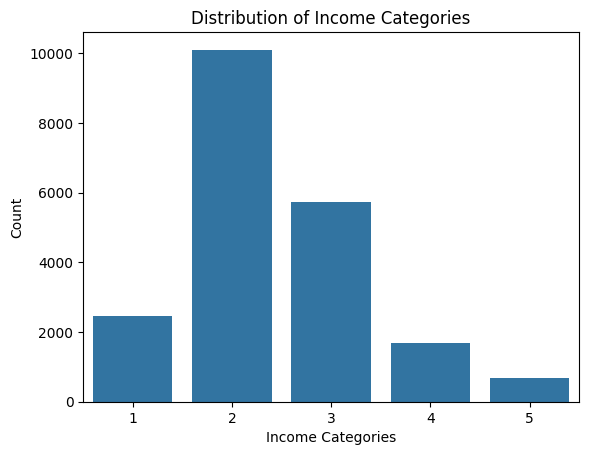

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt



sns.countplot(x='income_categories', data=df )
 
plt.title('Distribution of Income Categories')
plt.xlabel('Income Categories')
plt.ylabel('Count')



===================

==============

## Stratified Shuffle Split in Scikit-Learn

- Scikit-learn provides a built-in way to perform stratified sampling using StratifiedShuffleSplit.

Here’s how you can use it:

In [38]:


from sklearn.model_selection import StratifiedShuffleSplit


# Assume income_cat.. is a column in the dataset created from median_income
splitting = StratifiedShuffleSplit( n_splits = 1 , test_size = 0.2 , random_state = 42)



for train_split ,  test_split in splitting.split( df , df['income_categories'] ):
    train_data = df.loc[ train_split]
    test_data = df.loc[ test_split]



# This ensures that the income distribution in both sets is similar to that of the full dataset, 
# reducing sampling bias and making your model evaluation more reliable.


 Check the distribution of "income categories" in the original dataset, training set, and test set data

Text(0, 0.5, 'Count')

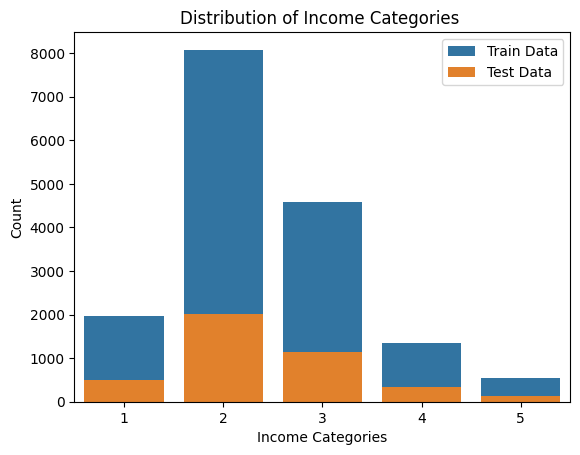

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='income_categories', data=train_data)

sns.countplot(x='income_categories', data=test_data)

plt.title('Distribution of Income Categories ')
plt.legend(['Train Data', 'Test Data'])
plt.xlabel('Income Categories')
plt.ylabel('Count')
